## 1. Import Library yang Dibutuhkan
Memuat pustaka komputasi numerik, pengolahan citra, machine learning, dan TensorFlow/Keras.

In [1]:
# Install library jika belum terpasang di Colab:
!pip install scikit-image opencv-python matplotlib seaborn scikit-learn joblib

import os
import time
import json
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

# Library Machine Learning & Evaluasi
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone

# Library Ekstraksi Fitur Tekstur GLCM
from skimage.feature import graycomatrix, graycoprops

# Library Deep Learning (TensorFlow / Keras)
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Random seed agar hasil konsisten
np.random.seed(42)
tf.random.set_seed(42)

print("Versi TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("Status Akselerasi:", "GPU Aktif" if gpus else "CPU (Standard)")

Versi TensorFlow: 2.21.0
Status Akselerasi: GPU Aktif


## 2. Pengaturan Path Dataset
Menghubungkan Google Drive dan memvalidasi direktori dataset citra tulisan tangan.

In [2]:
# Pengaturan direktori dataset
drive.mount('/content/drive')
DATASET_DIR = "/content/drive/MyDrive/Dataset_Citra_Tulisan_Tangan"

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATASET_DIR}")

print("Path dataset aktif:", os.path.abspath(DATASET_DIR))

Mounted at /content/drive
Path dataset aktif: /content/drive/MyDrive/Dataset_Citra_Tulisan_Tangan


## 3. Membaca Citra dan Label Kelas
Membaca direktori kelas dan memuat seluruh path citra tulisan tangan berserta labelnya.

In [3]:
image_paths = []
labels = []

kelas_list = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
print(f"Total kelas mahasiswa terdaftar: {len(kelas_list)}")

for kelas in kelas_list:
    kelas_dir = os.path.join(DATASET_DIR, kelas)
    for f in sorted(os.listdir(kelas_dir)):
        f_path = os.path.join(kelas_dir, f)
        # Ambil file gambar di root folder kelas (mengabaikan subfolder Original dan non-citra/PDF)
        if os.path.isfile(f_path) and f.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(f_path)
            labels.append(kelas)

print(f"Total citra tulisan tangan yang berhasil dimuat: {len(image_paths)}")

Total kelas mahasiswa terdaftar: 51
Total citra tulisan tangan yang berhasil dimuat: 2782


### Visualisasi Sampel Citra Tulisan Tangan
Menampilkan 6 sampel acak citra tulisan tangan beserta resolusi aslinya.

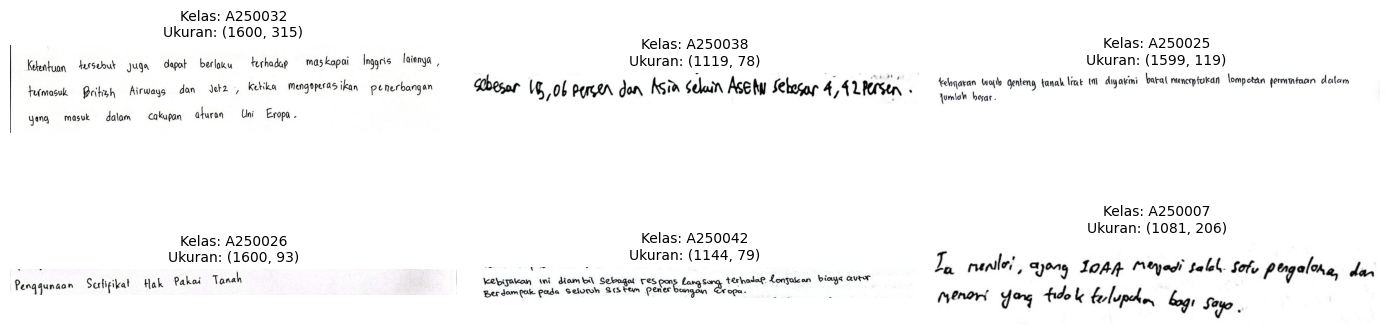

In [4]:
# Menampilkan 6 sampel citra secara acak
fig, axes = plt.subplots(2, 3, figsize=(14, 5))
sample_indices = np.random.choice(len(image_paths), 6, replace=False)

for idx, ax in zip(sample_indices, axes.flatten()):
    img = Image.open(image_paths[idx])
    ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
    ax.set_title(f"Kelas: {labels[idx]}\nUkuran: {img.size}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 4. Ekstraksi Fitur Tekstur GLCM (24 Fitur dengan Letterboxing)
Ekstraksi 24 fitur tekstur GLCM (6 properti Haralick $\times$ 4 arah) pada citra grayscale $128 \times 128$ dengan teknik letterboxing untuk menjaga proporsi goresan tulisan.

In [5]:
IMG_SIZE = (128, 128)

def resize_with_letterbox(img, target_size=IMG_SIZE, bg_color=(230, 230, 230)):
    """
    Mengubah ukuran citra dengan mempertahankan aspek rasio (letterbox),
    dan menempatkannya di tengah kanvas berukuran target_size dengan warna latar netral.
    """
    img_copy = img.copy()
    img_copy.thumbnail(target_size, Image.Resampling.LANCZOS)
    if img_copy.mode == 'L':
        fill_val = bg_color if isinstance(bg_color, int) else bg_color[0]
        canvas = Image.new('L', target_size, fill_val)
    else:
        fill_val = bg_color if isinstance(bg_color, tuple) else (bg_color, bg_color, bg_color)
        canvas = Image.new('RGB', target_size, fill_val)
        if img_copy.mode != 'RGB':
            img_copy = img_copy.convert('RGB')
    offset = ((target_size[0] - img_copy.size[0]) // 2, (target_size[1] - img_copy.size[1]) // 2)
    canvas.paste(img_copy, offset)
    return canvas

def extract_glcm(path_citra):
    raw_img = Image.open(path_citra)
    # Preprocessing letterbox & konversi ke Grayscale
    lb_img = resize_with_letterbox(raw_img, target_size=IMG_SIZE, bg_color=230)
    gray_img = lb_img.convert('L')
    img_arr = np.array(gray_img, dtype=np.uint8)

    # Hitung matriks GLCM
    glcm = graycomatrix(
        img_arr,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    # Ekstraksi 24 fitur (6 properti Haralick x 4 orientasi sudut)
    props = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    return [float(val) for p in props for val in graycoprops(glcm, p)[0]]

print("Memulai ekstraksi fitur tekstur GLCM (24 fitur per citra dengan letterbox)...")
t_awal_glcm = time.time()

X_glcm = np.array([extract_glcm(p) for p in image_paths])
waktu_ekstraksi_glcm = time.time() - t_awal_glcm

print(f"Waktu ekstraksi fitur GLCM : {waktu_ekstraksi_glcm:.2f} detik")
print(f"Rata-rata per citra        : {(waktu_ekstraksi_glcm / len(image_paths)):.4f} detik")
print(f"Dimensi array fitur GLCM   : {X_glcm.shape} (24 fitur)")

Memulai ekstraksi fitur tekstur GLCM (24 fitur per citra dengan letterbox)...
Waktu ekstraksi fitur GLCM : 1899.74 detik
Rata-rata per citra        : 0.6829 detik
Dimensi array fitur GLCM   : (2782, 24) (24 fitur)


## 5. Persiapan Data Deep Learning & Setup 5-Fold Cross Validation
Encoding label kelas, normalisasi tensor citra RGB $[0, 1]$ berukuran $128 \times 128$, serta inisialisasi 5-Fold Stratified Cross Validation.

In [6]:
# Label encoding kelas mahasiswa ke angka 0 s.d. 50
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
num_classes = len(le.classes_)

# Preprocessing citra RGB untuk Deep Learning dengan Letterboxing
print("Memuat citra untuk Deep Learning (menggunakan letterboxing)...")
X_images = np.array([
    np.array(resize_with_letterbox(Image.open(p), target_size=IMG_SIZE, bg_color=(230, 230, 230)).convert('RGB'), dtype=np.float32) / 255.0
    for p in image_paths
])
print("Dimensi tensor citra DL:", X_images.shape)

# Setup 5-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_folds = list(skf.split(X_glcm, y_encoded))
print("Siap menjalankan 5-Fold Cross Validation.")

# Helper fungsi evaluasi 5-Fold Cross Validation
def evaluate_kfold(name, model_fn, X, y, folds, is_keras=False, scale=False, fit_kwargs=None):
    """
    Menjalankan evaluasi 5-Fold Cross Validation:
    Menghitung Precision, Recall, Akurasi, F1-Score (macro), dan durasi pelatihan per fold,
    serta menghasilkan DataFrame lengkap beserta ringkasan baris 'Rata-Rata'.
    """
    results = []
    print(f"\nEvaluasi {name}:")
    fit_kwargs = fit_kwargs or {}

    for fold_no, (train_idx, test_idx) in enumerate(folds, start=1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_fn() if callable(model_fn) else clone(model_fn)

        t0 = time.time()
        model.fit(X_train, y_train, **fit_kwargs)
        durasi = time.time() - t0

        if is_keras:
            y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
        else:
            y_pred = model.predict(X_test)

        res = {
            'Eksperimen ke': fold_no,
            'Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Akurasi': round(accuracy_score(y_test, y_pred), 4),
            'F1-Score': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Waktu Pelatihan': round(durasi, 4)
        }
        results.append(res)
        print(f"Fold {fold_no} -> Akurasi: {res['Akurasi']} | Waktu: {durasi:.4f}s")

    df = pd.DataFrame(results)
    rata = {
        'Eksperimen ke': 'Rata-Rata',
        'Precision': round(df['Precision'].mean(), 4),
        'Recall': round(df['Recall'].mean(), 4),
        'Akurasi': round(df['Akurasi'].mean(), 4),
        'F1-Score': round(df['F1-Score'].mean(), 4),
        'Waktu Pelatihan': round(df['Waktu Pelatihan'].mean(), 4)
    }
    df_with_avg = pd.concat([df, pd.DataFrame([rata])], ignore_index=True)
    return df_with_avg, rata

Memuat citra untuk Deep Learning (menggunakan letterboxing)...
Dimensi tensor citra DL: (2782, 128, 128, 3)
Siap menjalankan 5-Fold Cross Validation.


## 6. Klasifikasi Machine Learning (+ GLCM)
### 6.1. Support Vector Machine (SVM) + GLCM
Pelatihan dan validasi model SVM kernel RBF ($C=10.0$) menggunakan fitur tekstur GLCM yang distandarisasi.

In [7]:
# Evaluasi 5-Fold Cross Validation untuk SVM + GLCM
df_svm, rata_svm = evaluate_kfold(
    "SVM + GLCM",
    lambda: SVC(kernel='rbf', C=10.0, random_state=42),
    X_glcm, y_encoded, k_folds, scale=True
)
display(df_svm)


Evaluasi SVM + GLCM:
Fold 1 -> Akurasi: 0.6786 | Waktu: 0.2395s
Fold 2 -> Akurasi: 0.6122 | Waktu: 0.2366s
Fold 3 -> Akurasi: 0.6331 | Waktu: 0.2589s
Fold 4 -> Akurasi: 0.6673 | Waktu: 0.2471s
Fold 5 -> Akurasi: 0.6403 | Waktu: 0.2382s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.6994,0.6759,0.6786,0.6742,0.2395
1,2,0.6584,0.6091,0.6122,0.6097,0.2366
2,3,0.6667,0.6299,0.6331,0.6216,0.2589
3,4,0.6825,0.6691,0.6673,0.6633,0.2471
4,5,0.6570,0.6433,0.6403,0.6340,0.2382
5,Rata-Rata,0.6728,0.6455,0.6463,0.6406,0.2441


### 6.2. Random Forest + GLCM
Pelatihan dan validasi model Random Forest (100 pohon keputusan) menggunakan fitur tekstur GLCM.

In [8]:
# Evaluasi 5-Fold Cross Validation untuk Random Forest + GLCM
df_rf, rata_rf = evaluate_kfold(
    "Random Forest + GLCM",
    lambda: RandomForestClassifier(n_estimators=100, random_state=42),
    X_glcm, y_encoded, k_folds
)
display(df_rf)


Evaluasi Random Forest + GLCM:
Fold 1 -> Akurasi: 0.605 | Waktu: 2.1320s
Fold 2 -> Akurasi: 0.6122 | Waktu: 2.6346s
Fold 3 -> Akurasi: 0.6097 | Waktu: 2.9074s
Fold 4 -> Akurasi: 0.6115 | Waktu: 2.1654s
Fold 5 -> Akurasi: 0.6025 | Waktu: 2.1723s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.6154,0.6039,0.6050,0.5979,2.1320
1,2,0.6302,0.6100,0.6122,0.6067,2.6346
2,3,0.6157,0.6051,0.6097,0.6041,2.9074
3,4,0.6175,0.6130,0.6115,0.6070,2.1654
4,5,0.6260,0.6048,0.6025,0.6013,2.1723
5,Rata-Rata,0.6210,0.6074,0.6082,0.6034,2.4023


## 7. Klasifikasi Deep Learning: Transfer Learning & Fine-Tuning (MobileNetV2)
Transfer learning arsitektur MobileNetV2 (ImageNet) dengan data augmentation dan fine-tuning 30 layer konvolusi teratas untuk klasifikasi citra.

In [9]:
def build_mobilenet(input_shape=(128, 128, 3), n_classes=num_classes):
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)

    # Fine-tuning: buka unfreeze pada 30 layer teratas agar belajar representasi goresan tulisan tangan
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False

    data_augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.06),
        layers.RandomContrast(0.12),
    ])

    inputs = tf.keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Evaluasi 5-Fold Cross Validation untuk MobileNetV2
df_mb, rata_mb = evaluate_kfold(
    "MobileNetV2",
    build_mobilenet,
    X_images, y_encoded, k_folds,
    is_keras=True,
    fit_kwargs={'epochs': 12, 'batch_size': 32, 'verbose': 0}
)
display(df_mb)


Evaluasi MobileNetV2:
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Fold 1 -> Akurasi: 0.3088 | Waktu: 57.4926s
Fold 2 -> Akurasi: 0.3106 | Waktu: 42.3418s
Fold 3 -> Akurasi: 0.2482 | Waktu: 45.0292s
Fold 4 -> Akurasi: 0.2716 | Waktu: 48.1198s
Fold 5 -> Akurasi: 0.4424 | Waktu: 43.5014s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.4040,0.2994,0.3088,0.2636,57.4926
1,2,0.4635,0.3199,0.3106,0.3080,42.3418
2,3,0.3755,0.2361,0.2482,0.2122,45.0292
3,4,0.3973,0.2781,0.2716,0.2521,48.1198
4,5,0.5515,0.4425,0.4424,0.4300,43.5014
5,Rata-Rata,0.4384,0.3152,0.3163,0.2932,47.2970


## 8. Rekapitulasi Hasil Evaluasi
Tabel perbandingan performa rata-rata (Precision, Recall, Akurasi, F1-Score, dan Waktu Pelatihan) dari ketiga model.

In [10]:
models_summary = [
    ('SVM + GLCM', rata_svm),
    ('Random Forest + GLCM', rata_rf),
    ('MobileNetV2', rata_mb)
]

df_rekapitulasi = pd.DataFrame([
    {
        'Model': name,
        'Rata-Rata Precision': summary['Precision'],
        'Rata-Rata Recall': summary['Recall'],
        'Rata-Rata Akurasi': summary['Akurasi'],
        'Rata-Rata F1-Score': summary['F1-Score'],
        'Rata-Rata Waktu Pelatihan': summary['Waktu Pelatihan']
    }
    for name, summary in models_summary
])

print("Ringkasan Hasil Evaluasi:")
display(df_rekapitulasi)
print(f"Total waktu ekstraksi fitur GLCM: {waktu_ekstraksi_glcm:.2f} detik")

Ringkasan Hasil Evaluasi:


,Model,Rata-Rata Precision,Rata-Rata Recall,Rata-Rata Akurasi,Rata-Rata F1-Score,Rata-Rata Waktu Pelatihan
0,SVM + GLCM,0.6728,0.6455,0.6463,0.6406,0.2441
1,Random Forest + GLCM,0.6210,0.6074,0.6082,0.6034,2.4023
2,MobileNetV2,0.4384,0.3152,0.3163,0.2932,47.2970


Total waktu ekstraksi fitur GLCM: 1899.74 detik


## 9. Visualisasi Grafik Perbandingan Model
Visualisasi grafik batang perbandingan metrik evaluasi dan efisiensi waktu komputasi antar model.

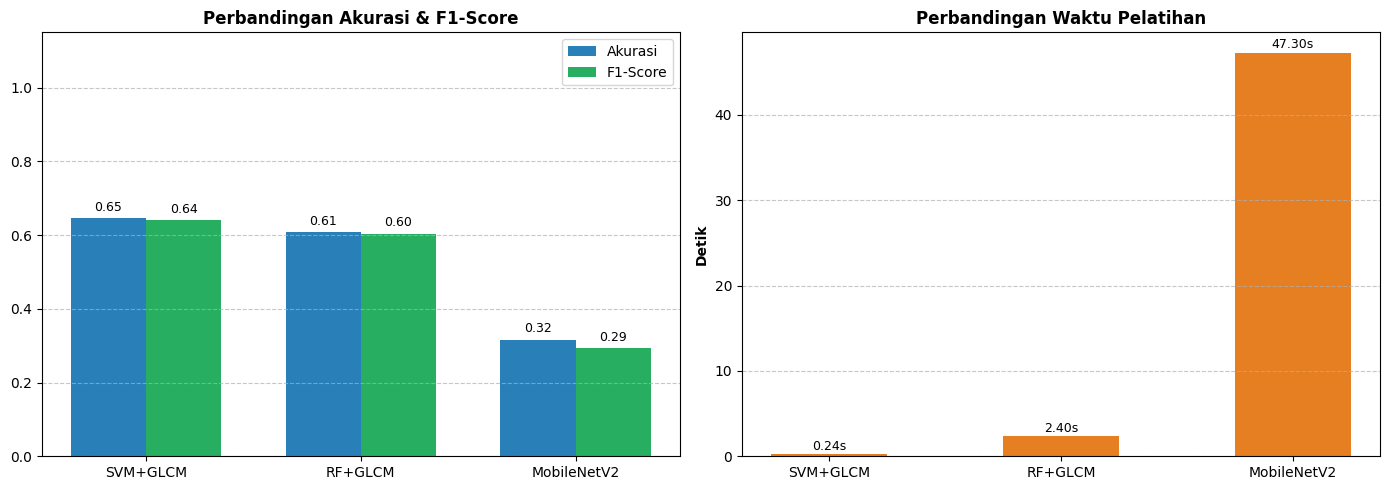

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
models_name = ['SVM+GLCM', 'RF+GLCM', 'MobileNetV2']

# Grafik 1: Akurasi & F1-Score
acc_vals = [rata_svm['Akurasi'], rata_rf['Akurasi'], rata_mb['Akurasi']]
f1_vals = [rata_svm['F1-Score'], rata_rf['F1-Score'], rata_mb['F1-Score']]
x = np.arange(len(models_name))
w = 0.35

ax1.bar(x - w/2, acc_vals, w, label='Akurasi', color='#2980b9')
ax1.bar(x + w/2, f1_vals, w, label='F1-Score', color='#27ae60')
ax1.set_xticks(x)
ax1.set_xticklabels(models_name)
ax1.set_ylim(0, 1.15)
ax1.set_title('Perbandingan Akurasi & F1-Score', fontweight='bold')
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)
for i in range(len(models_name)):
    ax1.text(x[i] - w/2, acc_vals[i] + 0.02, f"{acc_vals[i]:.2f}", ha='center', fontsize=9)
    ax1.text(x[i] + w/2, f1_vals[i] + 0.02, f"{f1_vals[i]:.2f}", ha='center', fontsize=9)

# Grafik 2: Waktu Pelatihan
waktu_vals = [rata_svm['Waktu Pelatihan'], rata_rf['Waktu Pelatihan'], rata_mb['Waktu Pelatihan']]
ax2.bar(models_name, waktu_vals, color='#e67e22', width=0.5)
ax2.set_ylabel('Detik', fontweight='bold')
ax2.set_title('Perbandingan Waktu Pelatihan', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(waktu_vals):
    ax2.text(i, v + (max(waktu_vals)*0.01 if max(waktu_vals) > 0 else 0.01), f"{v:.2f}s", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 10. Pelatihan Model Final (100% Data) & Export Model
Pelatihan ulang seluruh model pada 100% data dan penyimpanan artefak (bobot model, scaler, pemetaan kelas, dan metadata) untuk kebutuhan backend.

In [12]:
# Pengaturan direktori penyimpanan model untuk FastAPI
EXPORT_DIR = "model_export"
os.makedirs(EXPORT_DIR, exist_ok=True)
print(f"Direktori ekspor aktif: {os.path.abspath(EXPORT_DIR)}")

# 1. Export Pemetaan Label (classes.json)
class_mapping = {int(idx): str(label) for idx, label in enumerate(le.classes_)}
with open(os.path.join(EXPORT_DIR, "classes.json"), "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=4)

# Export LabelEncoder objek
joblib.dump(le, os.path.join(EXPORT_DIR, "label_encoder.joblib"))

# 2. Export Metadata Preprocessing & Konfigurasi Citra
metadata = {
    "num_classes": int(num_classes),
    "classes": list(map(str, le.classes_)),
    "image_size": list(IMG_SIZE),
    "channels": 3,
    "normalization": "div_255",
    "preprocessing": "letterbox_128x128",
    "num_glcm_features": 24,
    "glcm_config": {
        "properties": ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM'],
        "distances": [1],
        "angles": [0, 45, 90, 135],
        "total_features": 24
    }
}
with open(os.path.join(EXPORT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("[OK] classes.json, label_encoder.joblib, dan metadata.json berhasil diekspor.")

Direktori ekspor aktif: /content/model_export
[OK] classes.json, label_encoder.joblib, dan metadata.json berhasil diekspor.


In [13]:
print("1. Melatih ulang MobileNetV2 pada 100% dataset (Fine-Tuned + Letterbox)...")

# Inisialisasi arsitektur MobileNetV2 baru
final_mobilenet = build_mobilenet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), n_classes=num_classes)

# Latih pada seluruh data citra (15 epochs dengan data augmentation)
t_start_train_mb = time.time()
final_mobilenet.fit(X_images, y_encoded, epochs=15, batch_size=32, verbose=1)
waktu_train_mb = time.time() - t_start_train_mb
print(f"Pelatihan MobileNetV2 selesai dalam {waktu_train_mb:.2f} detik.")

# Simpan dalam format native modern Keras (.keras) dan legacy HDF5 (.h5)
keras_path = os.path.join(EXPORT_DIR, "mobilenetv2_final.keras")
h5_path = os.path.join(EXPORT_DIR, "mobilenetv2_final.h5")

final_mobilenet.save(keras_path)
print(f"[EXPORTED] Format modern Keras : {keras_path}")

try:
    final_mobilenet.save(h5_path)
    print(f"[EXPORTED] Format HDF5 (.h5)  : {h5_path}")
except Exception as e:
    print(f"[Catatan] Ekspor format .h5 dilewati: {e}")

1. Melatih ulang MobileNetV2 pada 100% dataset (Fine-Tuned + Letterbox)...
Epoch 1/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.2451 - loss: 3.0531
Epoch 2/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.4694 - loss: 1.9389
Epoch 3/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.5766 - loss: 1.4566
Epoch 4/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6272 - loss: 1.2348
Epoch 5/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.6848 - loss: 1.0699
Epoch 6/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.6977 - loss: 0.9839
Epoch 7/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7265 - loss: 0.8649
Epoch 8/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7599 - loss: 0.7669
Epoch 9/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7595 - loss: 0.7636
Epoch 10/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.7865 - loss: 0.6806
Epoch 11/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.8174 - 

[EXPORTED] Format modern Keras : model_export/mobilenetv2_final.keras
[EXPORTED] Format HDF5 (.h5)  : model_export/mobilenetv2_final.h5


In [14]:
print("2. Melatih ulang SVM & Random Forest pada 100% dataset (24 fitur GLCM)...")

# A. Fit StandardScaler pada seluruh data GLCM (24 fitur)
final_scaler = StandardScaler()
X_glcm_scaled = final_scaler.fit_transform(X_glcm)
scaler_path = os.path.join(EXPORT_DIR, "glcm_scaler.joblib")
joblib.dump(final_scaler, scaler_path)
print(f"[EXPORTED] Scaler GLCM (24 features): {scaler_path}")

# B. Latih SVM pada seluruh data GLCM (24 fitur)
# probability=True digunakan agar model SVM dapat menghasilkan confidence score (predict_proba) di FastAPI
print("Melatih Final SVM...")
t_start_svm = time.time()
final_svm = SVC(kernel='rbf', C=10.0, probability=True, random_state=42)
final_svm.fit(X_glcm_scaled, y_encoded)
waktu_train_svm = time.time() - t_start_svm
svm_path = os.path.join(EXPORT_DIR, "svm_glcm_final.joblib")
joblib.dump(final_svm, svm_path)
print(f"[EXPORTED] Final SVM Model    : {svm_path} (Pelatihan: {waktu_train_svm:.2f}s)")

# C. Latih Random Forest pada seluruh data GLCM (24 fitur)
print("Melatih Final Random Forest...")
t_start_rf = time.time()
final_rf = RandomForestClassifier(n_estimators=100, random_state=42)
final_rf.fit(X_glcm, y_encoded)
waktu_train_rf = time.time() - t_start_rf
rf_path = os.path.join(EXPORT_DIR, "rf_glcm_final.joblib")
joblib.dump(final_rf, rf_path)
print(f"[EXPORTED] Final Random Forest: {rf_path} (Pelatihan: {waktu_train_rf:.2f}s)")

2. Melatih ulang SVM & Random Forest pada 100% dataset (24 fitur GLCM)...
[EXPORTED] Scaler GLCM (24 features): model_export/glcm_scaler.joblib
Melatih Final SVM...
[EXPORTED] Final SVM Model    : model_export/svm_glcm_final.joblib (Pelatihan: 1.91s)
Melatih Final Random Forest...
[EXPORTED] Final Random Forest: model_export/rf_glcm_final.joblib (Pelatihan: 2.72s)


In [15]:
# Membuat arsip .zip dari direktori model_export
zip_output = shutil.make_archive("model_export", 'zip', EXPORT_DIR)
print(f"Direktori ekspor telah dikompres menjadi: {zip_output}")
print("Anda dapat mengunduh file 'model_export.zip' ini untuk dipindahkan ke folder backend FastAPI Anda.")

from google.colab import files
files.download("model_export.zip")

Direktori ekspor telah dikompres menjadi: /content/model_export.zip
Anda dapat mengunduh file 'model_export.zip' ini untuk dipindahkan ke folder backend FastAPI Anda.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>